In [1]:
!pip install -q pytorch-fid roboflow ultralytics

from roboflow import Roboflow
from google.colab import userdata, drive
import os

!git clone https://github.com/PaweekornS/underwater_sonar.git -b procedural

rf = Roboflow(api_key=userdata.get("ROBOFLOW"))
project = rf.workspace("yeesonmin-naver-com").project("cylider2")
dataset = project.version("6").download("yolov7")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.0/250.0 kB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 50.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 80.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 89.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 130.0 MB/s eta 0:00:00
Cloning into 'underwater_sonar'...
remote: Enumerating objects: 8652, done.
remote: Counting objects: 100% (3371/3371), done.
remote: Compressing objects: 100% (2288/2288), done.
remote: Total 8652 (delta 1120), reused 3322 (delta 1083), pack-reused 5281 (from 1)
Receiving objects: 100% (8652/8652), 369.11 MiB | 20.04 MiB/s, done.
Resolving deltas: 100% (1575/1575), done.
Updating files: 100% (6860/6860), done.
loading Roboflow workspace...
loadi


Extracting Dataset Version Zip to cylider2-6 in yolov7pytorch:: 100%|██████████| 968/968 [00:00<00:00, 2065.86it/s]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

from tqdm import tqdm
import glob
import sys

sys.path.append("./underwater_sonar/synthetic")
from utils.synth import place_single_object, place_multiple_objects
from utils.viz import visualize_bboxes

In [3]:
BASE_DIR = "/content/underwater_sonar/data/klsg_prep"
CLASS_MAP = {
    "cylinder": 0,
    "manta": 1,
    "plane": 2,
    "ship": 3,
    "victim": 4,
    "fish": -1,
    "MILCO": -1,
    "NOMBO": -1
}

## Image synthetic

### Demo

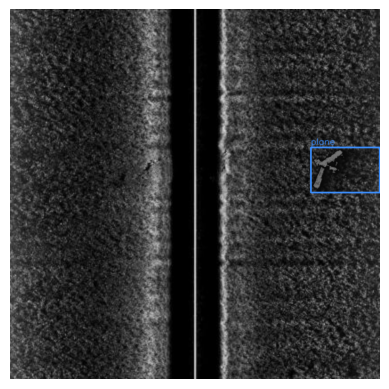

In [4]:
segment_files = np.sort(glob.glob("./underwater_sonar/data/final_prep/masked/plane/*"))
bg_files = glob.glob("./underwater_sonar/data/klsg_dataset/mine/*") + glob.glob("/content/cylider2*/*/images/*")

composed, bbox = place_single_object(bg_files[0], segment_files[0], classes=CLASS_MAP,
                                     filename="ship-001", save=False,
                                     output_dir="./synth_data/")

class_names = {v:k for k, v in CLASS_MAP.items()}
visualize_bboxes(composed, [bbox], color=(253, 142, 60), class_names=class_names)

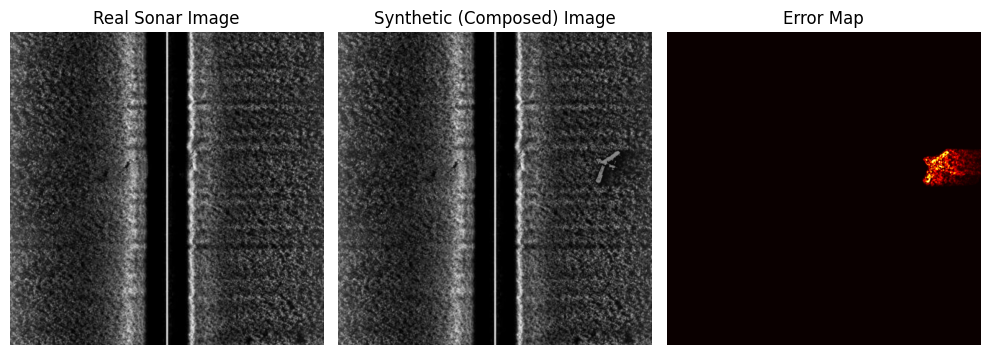

In [5]:
bg_img = cv2.imread(bg_files[0], cv2.IMREAD_GRAYSCALE)

# Ensure both images are the same size. `composed` was likely created with a specific size.
if bg_img.shape != composed.shape:
    bg_img_resized = cv2.resize(bg_img, (composed.shape[1], composed.shape[0]))
else:
    bg_img_resized = bg_img

# Calculate the absolute difference (error map)
error_map = np.abs(composed.astype(np.float32) - bg_img_resized.astype(np.float32))

# Normalize the error map for better visualization (optional)
error_map_display = cv2.normalize(error_map, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

plt.figure(figsize=(10, 5))
plt.subplot(1, 3, 1)
plt.title("Real Sonar Image")
plt.imshow(bg_img_resized, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("Synthetic (Composed) Image")
plt.imshow(composed, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("Error Map")
plt.imshow(error_map_display, cmap='hot') # Using 'hot' colormap to highlight differences
plt.axis('off')

plt.tight_layout()
plt.show()

### Single Object

In [16]:
synth_count = {
    "cylinder": 226,
    "manta": 404,
    "plane": 428,
    "ship": 163,
    "victim": 313,
}

segment_files = []
selected_bg = []
for class_name, count in synth_count.items():
    print(f"Synthesizing {class_name}: {count} images")
    segment_obj = np.sort(glob.glob(f"/content/underwater_sonar/data/final_prep/masked/{class_name}/*"))
    segment_files.extend(segment_obj)

    bg_files = glob.glob("underwater_sonar/data/klsg_dataset/mine/*") + glob.glob("/content/cylider2*/*/images/*")
    if class_name in ["cylinder", "manta"]:
        bg_files = glob.glob("/content/cylider2*/*/images/*")

    # train
    for i in tqdm(range(count)):
        bg_file = np.random.choice(bg_files)
        segment_file = np.random.choice(segment_obj)
        composed, bbox = place_single_object(
            bg_file, segment_file, classes=CLASS_MAP,
            output_dir="/content/synth_data/", filename=f"{class_name}-{i+1:03d}", save=True
        )

        selected_bg.append(bg_file)

Synthesizing cylinder: 226 images


100%|██████████| 226/226 [00:07<00:00, 30.37it/s]


Synthesizing manta: 404 images


100%|██████████| 404/404 [00:13<00:00, 30.87it/s]


Synthesizing plane: 428 images


100%|██████████| 428/428 [00:14<00:00, 29.80it/s]


Synthesizing ship: 163 images


100%|██████████| 163/163 [00:06<00:00, 23.79it/s]


Synthesizing victim: 313 images


100%|██████████| 313/313 [00:19<00:00, 16.22it/s]


### Multiple object

100%|██████████| 50/50 [00:03<00:00, 12.64it/s]


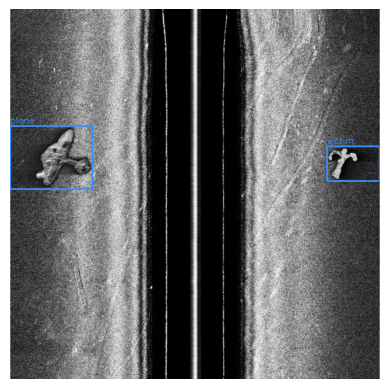

In [17]:
for i in tqdm(range(50)):
    composed, bboxes, class_ids = place_multiple_objects(
        bg_files, segment_files,
        classes=CLASS_MAP, max_objects=4,
        filename=f"mixed-{i+1:03d}", save=True,
        output_dir="./synth_data/"
    )

visualize_bboxes(composed, bboxes, color=(253, 142, 60), class_names=class_names)

## Evaluation

In [19]:
os.makedirs("./eval_dataset/real", exist_ok=True)
os.makedirs("./eval_dataset/synth", exist_ok=True)

real_data = selected_bg
synth_data = glob.glob("synth_data/images/*")

for file in tqdm(real_data):
    img = cv2.imread(file, 0)
    img = cv2.resize(img, (640, 640))
    cv2.imwrite(f"./eval_dataset/real/{os.path.basename(file)}", img)

for file in tqdm(synth_data):
    img = cv2.imread(file, 0)
    cv2.imwrite(f"./eval_dataset/synth/{os.path.basename(file)}", img)

100%|██████████| 1584/1584 [00:19<00:00, 79.75it/s]


In [20]:
from eval import calculate_metrics
import torch

BACKGROUND_DIR = "./eval_dataset/real/"
OUTPUT_DIR = "./eval_dataset/synth/"

# call evaluation
fid, ssim_score, psnr_score = calculate_metrics(
    BACKGROUND_DIR, OUTPUT_DIR,
    device="cuda" if torch.cuda.is_available() else "cpu",
    batch_size=32
)

print(f"FID: {fid:.4f}")
print(f"SSIM: {ssim_score:.4f}")
print(f"PSNR: {psnr_score:.4f}")

100%|██████████| 50/50 [00:19<00:00,  2.58it/s]


FID: 22.0162
SSIM: 0.1425
PSNR: 12.6354
